# Tópico 14 - Região de Convergência (ROC)

## Visão Geral e Objetivos
Neste notebook, investigamos a **Região de Convergência (ROC - Region of Convergence)** da Transformada-Z. Os principais objetivos são:
1. **Unicidade da Transformada-Z**: Demonstrar que uma expressão algébrica $X(z)$ não especifica um sinal no tempo de forma única sem a definição explícita de sua ROC.
2. **Sinais Causais vs. Anti-causais**:
   - Sinal Causal: $x_1[n] = a^n u[n] \stackrel{\mathcal{Z}}{\longleftrightarrow} X_1(z) = \frac{z}{z-a}$, com $\text{ROC}_1: |z| > |a|$.
   - Sinal Anti-causal: $x_2[n] = -a^n u[-n-1] \stackrel{\mathcal{Z}}{\longleftrightarrow} X_2(z) = \frac{z}{z-a}$, com $\text{ROC}_2: |z| < |a|$.
3. **Propriedades da ROC**:
   - A ROC é uma região anelar ou circular centrada na origem do plano-$z$.
   - A ROC **não contém nenhum polo**.
   - Para sinais causais, a ROC é o exterior de um círculo delimitado pelo polo de maior módulo.
   - Para a estabilidade BIBO, a ROC deve conter o círculo unitário ($|z| = 1$).
4. **Gerenciamento de Figuras**: Exportar os gráficos gerados diretamente para o diretório local de simulação.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Garantir a criação do diretório local para exportação das imagens
os.makedirs(".", exist_ok=True)

## 1. Simulação Temporal: Sinal Causal vs. Anti-causal

Analisamos o parâmetro $a = 0.8$:
1. **Sinal Causal ($n \ge 0$)**: $x_1[n] = 0.8^n u[n]$
2. **Sinal Anti-causal ($n < 0$)**: $x_2[n] = -0.8^n u[-n-1]$

Ambos possuem exatamente a mesma representação algébrica $X(z) = \frac{1}{1 - 0.8 z^{-1}} = \frac{z}{z - 0.8}$, mas possuem domínios de convergência completamente opostos no plano complexo $z$.

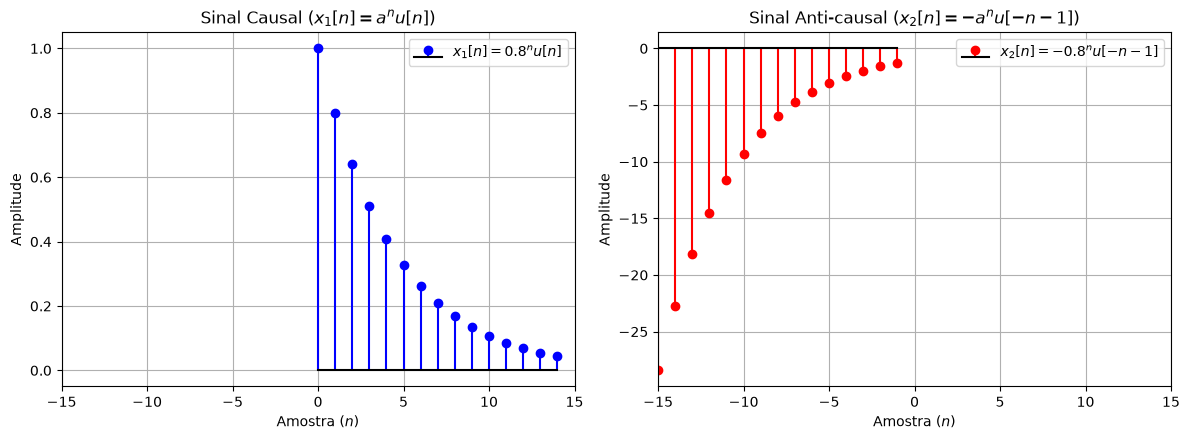

In [2]:
# Parâmetro da exponencial
a = 0.8

# Índices de amostragem
n_pos = np.arange(0, 15)
n_neg = np.arange(-15, 0)

# Sinais no domínio do tempo
x_causal = a**n_pos
x_anticausal = -(a**n_neg)

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot do Sinal Causal
ax1.stem(n_pos, x_causal, linefmt='b-', markerfmt='bo', basefmt='k-', label=r'$x_1[n] = 0.8^n u[n]$')
ax1.set_title(r'Sinal Causal ($x_1[n] = a^n u[n]$)')
ax1.set_xlabel('Amostra ($n$)')
ax1.set_ylabel('Amplitude')
ax1.set_xlim(-15, 15)
ax1.grid(True)
ax1.legend()

# Plot do Sinal Anti-causal
ax2.stem(n_neg, x_anticausal, linefmt='r-', markerfmt='ro', basefmt='k-', label=r'$x_2[n] = -0.8^n u[-n-1]$')
ax2.set_title(r'Sinal Anti-causal ($x_2[n] = -a^n u[-n-1]$)')
ax2.set_xlabel('Amostra ($n$)')
ax2.set_ylabel('Amplitude')
ax2.set_xlim(-15, 15)
ax2.grid(True)
ax2.legend()

plt.tight_layout()
fig1.savefig("grafico_roc_tempo.png")
plt.show()

## 2. Mapeamento da Região de Convergência no Plano-$z$

Abaixo, plotamos o mapa de polos e zeros com a hachura das respectivas ROCs:
- **ROC Causal ($\text{ROC}_1$)**: $|z| > 0.8$ (Região exterior ao polo em $z = 0.8$). Como $|a| = 0.8 < 1$, o círculo unitário ($|z| = 1$) está contido na ROC, confirmando que a sequência causal é **estável**.
- **ROC Anti-causal ($\text{ROC}_2$)**: $|z| < 0.8$ (Região interior ao polo em $z = 0.8$). O círculo unitário não está contido na ROC, tornando a sequência anti-causal **instável**.

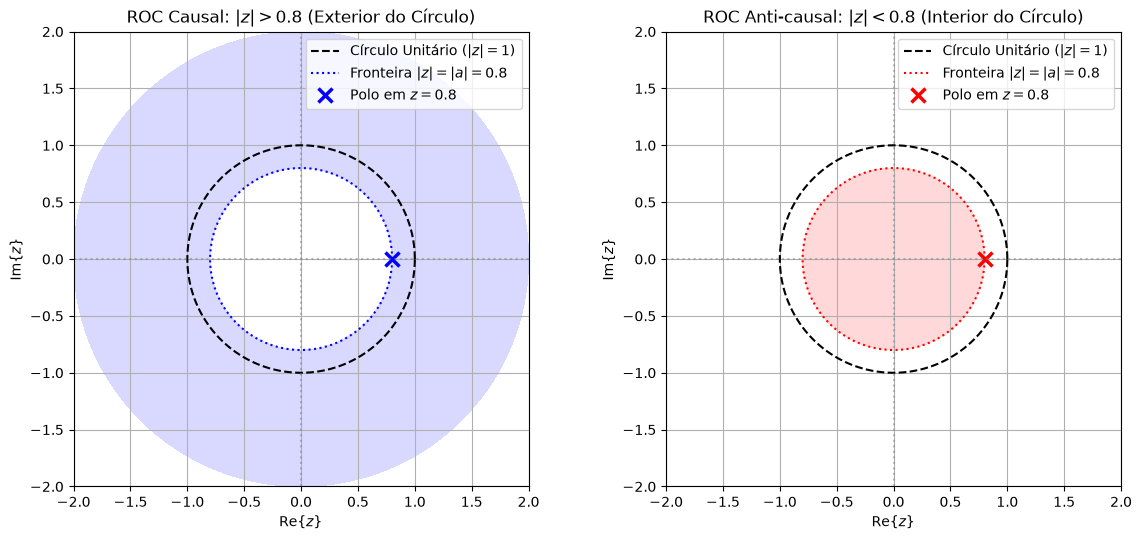

In [3]:
fig2, (ax_c, ax_ac) = plt.subplots(1, 2, figsize=(12, 5.5))

theta = np.linspace(0, 2 * np.pi, 200)
r_pole = np.abs(a)

# 1. ROC Causal: |z| > |a|
ax_c.plot(np.cos(theta), np.sin(theta), 'k--', linewidth=1.5, label='Círculo Unitário ($|z|=1$)')
ax_c.plot(r_pole * np.cos(theta), r_pole * np.sin(theta), 'b:', linewidth=1.5, label=r'Fronteira $|z| = |a| = 0.8$')

# Hachurar a região exterior |z| > 0.8
r_outer = np.linspace(r_pole, 2.0, 100)
T, R = np.meshgrid(theta, r_outer)
X_c, Y_c = R * np.cos(T), R * np.sin(T)
ax_c.contourf(X_c, Y_c, R, levels=[r_pole, 2.0], colors=['blue'], alpha=0.15)

ax_c.plot(a, 0, 'bx', markersize=10, markeredgewidth=2.5, label=r'Polo em $z = 0.8$')
ax_c.axhline(0, color='gray', linestyle=':', alpha=0.5)
ax_c.axvline(0, color='gray', linestyle=':', alpha=0.5)
ax_c.set_title(r'ROC Causal: $|z| > 0.8$ (Exterior do Círculo)')
ax_c.set_xlabel(r'$\text{Re}\{z\}$')
ax_c.set_ylabel(r'$\text{Im}\{z\}$')
ax_c.set_xlim(-2, 2)
ax_c.set_ylim(-2, 2)
ax_c.set_aspect('equal')
ax_c.grid(True)
ax_c.legend(loc='upper right')

# 2. ROC Anti-causal: |z| < |a|
ax_ac.plot(np.cos(theta), np.sin(theta), 'k--', linewidth=1.5, label='Círculo Unitário ($|z|=1$)')
ax_ac.plot(r_pole * np.cos(theta), r_pole * np.sin(theta), 'r:', linewidth=1.5, label=r'Fronteira $|z| = |a| = 0.8$')

# Hachurar a região interior |z| < 0.8
r_inner = np.linspace(0, r_pole, 100)
T_in, R_in = np.meshgrid(theta, r_inner)
X_ac, Y_ac = R_in * np.cos(T_in), R_in * np.sin(T_in)
ax_ac.contourf(X_ac, Y_ac, R_in, levels=[0, r_pole], colors=['red'], alpha=0.15)

ax_ac.plot(a, 0, 'rx', markersize=10, markeredgewidth=2.5, label=r'Polo em $z = 0.8$')
ax_ac.axhline(0, color='gray', linestyle=':', alpha=0.5)
ax_ac.axvline(0, color='gray', linestyle=':', alpha=0.5)
ax_ac.set_title(r'ROC Anti-causal: $|z| < 0.8$ (Interior do Círculo)')
ax_ac.set_xlabel(r'$\text{Re}\{z\}$')
ax_ac.set_ylabel(r'$\text{Im}\{z\}$')
ax_ac.set_xlim(-2, 2)
ax_ac.set_ylim(-2, 2)
ax_ac.set_aspect('equal')
ax_ac.grid(True)
ax_ac.legend(loc='upper right')

plt.tight_layout()
fig2.savefig("grafico_roc_plano_z.png")
plt.show()

## 3. Síntese dos Resultados sobre Região de Convergência (ROC)
- **Necessidade da ROC**: A expressão algébrica $X(z)$ é incompleta sem a especificação de sua ROC; sinais diferentes no tempo (causais vs. anti-causais) podem compartilhar a mesma forma algébrica em $z$.
- **Fronteira da ROC**: A ROC é sempre delimitada por círculos centrados na origem e **nunca contém polos**.
- **Causalidade e Estabilidade**: Um sistema LTI discreto é causal se sua ROC se estende para fora do polo de maior módulo; ele é BIBO estável se sua ROC abrange o círculo unitário ($|z| = 1$).